# Projeto N3 — Previsão de sucesso de vendas de videogames

**Problema:** dado um jogo (plataforma, gênero, publisher e ano), prever se ele será um **sucesso de vendas**
(vendas globais acima do percentil 75). Como comparação, também prevemos o valor de `Global_Sales` (regressão).

**Quem poderia usar:** publishers e estúdios que avaliam o potencial comercial de um lançamento.

**Fonte dos dados:** Kaggle — [Video_games_sales](https://www.kaggle.com/competitions/video-games-sales/overview)

**Integrantes e contribuições:** _Guilherme Oechsler, Jeliel Flores Moura, José Mateus Coelho Loose_

---
**Roteiro do notebook**
1. Carregar dados  2. Exploração (EDA)  3. Limpeza  4. Alvo e features  5. Modelagem (baseline + modelos + ajuste)
6. Avaliação  7. Análise de erros  8. Regressão (comparação)  9. Demonstração de uso  10. Conclusões

## 1. Configuração e carga dos dados

In [11]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


DATA_PATH = "/kaggle/input/competitions/video-games-sales/Video_Games_Sales_as_at_22_Dec_2016.csv"        
COL_TARGET = "Global_Sales"
COL_NAME = "Name"
CAT_FEATURES = ["Platform", "Genre", "Publisher"]
NUM_FEATURES = ["Year_of_Release"]
HIT_QUANTILE = 0.75


def make_preprocessor():
    """Pré-processamento: one-hot nas categóricas (categorias raras agrupadas) e escala no ano."""
    cat = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # min_frequency agrupa publishers raros; sparse_output=False porque o HistGradientBoosting não aceita matriz esparsa
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)),
    ])
    num = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    return ColumnTransformer([("cat", cat, CAT_FEATURES), ("num", num, NUM_FEATURES)])


In [12]:
if DATA_PATH is None:
    candidatos = []
    for root in ["/kaggle/input", "."]:
        for f in glob.glob(os.path.join(root, "**", "*.csv"), recursive=True):
            try:
                cols = pd.read_csv(f, nrows=1).columns
            except Exception:
                continue
            print("CSV encontrado:", f, "->", len(cols), "colunas")
            if COL_TARGET in cols:
                candidatos.append(f)
    assert candidatos, f"Nenhum CSV com a coluna '{COL_TARGET}'. Defina DATA_PATH manualmente."
    # prefere arquivos de treino
    candidatos.sort(key=lambda p: ("train" not in os.path.basename(p).lower(), p))
    DATA_PATH = candidatos[0]

print("\nUsando:", DATA_PATH)
df_raw = pd.read_csv(DATA_PATH)
print(df_raw.shape)
df_raw.head()


Usando: /kaggle/input/competitions/video-games-sales/Video_Games_Sales_as_at_22_Dec_2016.csv
(16719, 16)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploração dos dados (EDA)

In [13]:
print("Valores nulos por coluna:")
print(df_raw.isna().sum())
print("\nLinhas duplicadas:", df_raw.duplicated().sum())
df_raw.describe(include="all").T

Valores nulos por coluna:
Name                  2
Platform              0
Year_of_Release     269
Genre                 2
Publisher            54
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8582
Critic_Count       8582
User_Score         6704
User_Count         9129
Developer          6623
Rating             6769
dtype: int64

Linhas duplicadas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,16717,11562,Need for Speed: Most Wanted,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,16719,31,PS2,2161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Release,16450.0,NaN,NaN,NaN,2006.487356,5.878995,1980.0,2003.0,2007.0,2010.0,2020.0
Genre,16717,12,Action,3370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Publisher,16665,581,Electronic Arts,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NA_Sales,16719.0,NaN,NaN,NaN,0.26333,0.813514,0.0,0.0,0.08,0.24,41.36
EU_Sales,16719.0,NaN,NaN,NaN,0.145025,0.503283,0.0,0.0,0.02,0.11,28.96
JP_Sales,16719.0,NaN,NaN,NaN,0.077602,0.308818,0.0,0.0,0.0,0.04,10.22
Other_Sales,16719.0,NaN,NaN,NaN,0.047332,0.18671,0.0,0.0,0.01,0.03,10.57
Global_Sales,16719.0,NaN,NaN,NaN,0.533543,1.547935,0.01,0.06,0.17,0.47,82.53


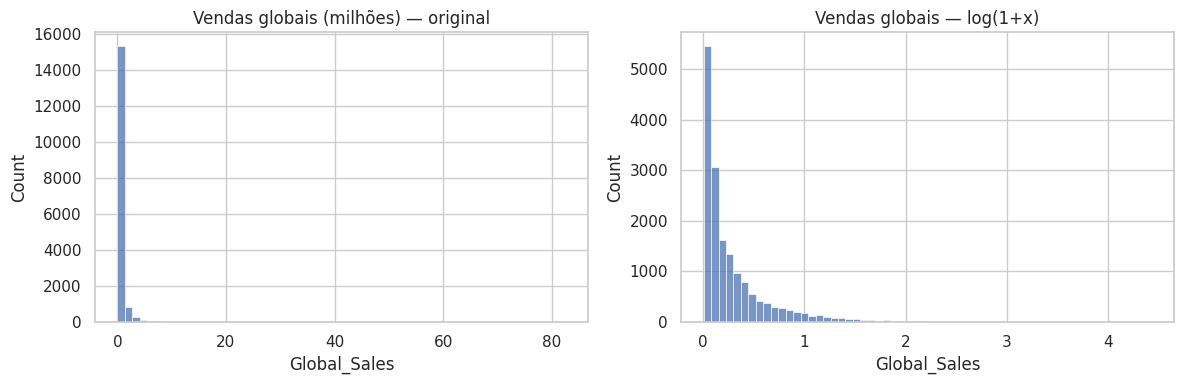

count    16719.000000
mean         0.533543
std          1.547935
min          0.010000
50%          0.170000
75%          0.470000
90%          1.200000
99%          5.458200
max         82.530000
Name: Global_Sales, dtype: float64


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_raw[COL_TARGET], bins=60, ax=ax[0]); ax[0].set_title("Vendas globais (milhões) — original")
sns.histplot(np.log1p(df_raw[COL_TARGET]), bins=60, ax=ax[1]); ax[1].set_title("Vendas globais — log(1+x)")
plt.tight_layout(); plt.show()
print(df_raw[COL_TARGET].describe(percentiles=[.5, .75, .9, .99]))

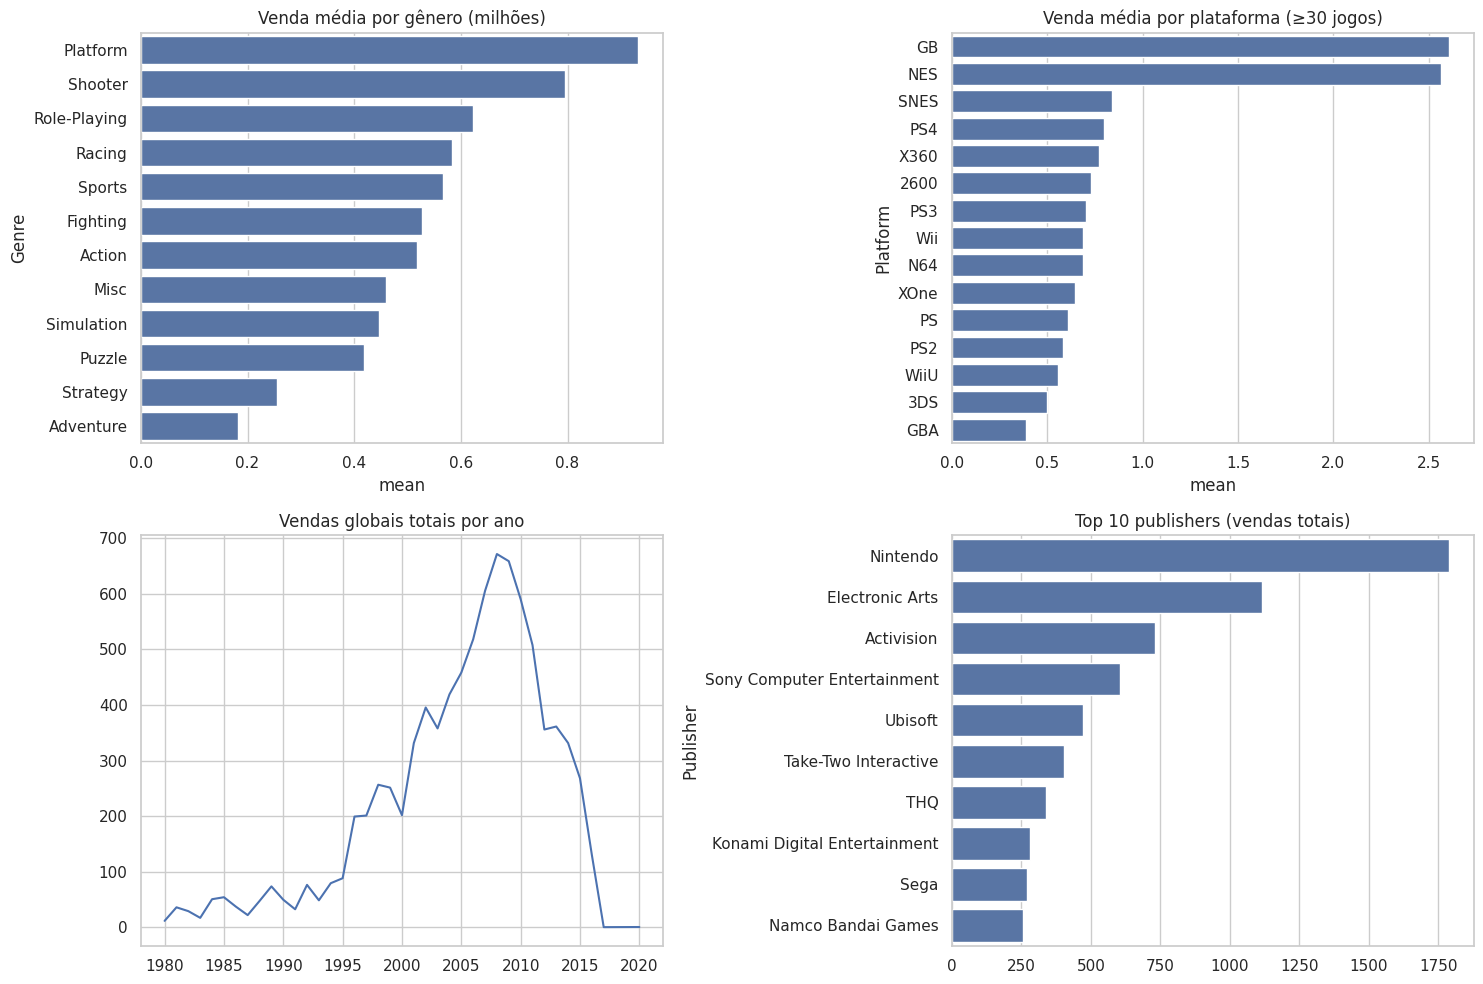

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
g = df_raw.groupby("Genre")[COL_TARGET].agg(["count", "mean"]).sort_values("mean", ascending=False)
sns.barplot(x=g["mean"], y=g.index, ax=ax[0, 0]); ax[0, 0].set_title("Venda média por gênero (milhões)")

p = df_raw.groupby("Platform")[COL_TARGET].agg(["count", "mean"])
p = p[p["count"] >= 30].sort_values("mean", ascending=False).head(15)
sns.barplot(x=p["mean"], y=p.index, ax=ax[0, 1]); ax[0, 1].set_title("Venda média por plataforma (≥30 jogos)")

y = pd.to_numeric(df_raw["Year_of_Release"], errors="coerce")
tot = df_raw.assign(Year=y).groupby("Year")[COL_TARGET].sum()
ax[1, 0].plot(tot.index, tot.values); ax[1, 0].set_title("Vendas globais totais por ano")

pub = df_raw.groupby("Publisher")[COL_TARGET].sum().sort_values(ascending=False).head(10)
sns.barplot(x=pub.values, y=pub.index, ax=ax[1, 1]); ax[1, 1].set_title("Top 10 publishers (vendas totais)")
plt.tight_layout(); plt.show()

## 3. Limpeza dos dados

In [16]:
df = df_raw.copy()
df = df.drop_duplicates()
df["Year_of_Release"] = pd.to_numeric(df["Year_of_Release"], errors="coerce")

n0 = len(df)
df = df.dropna(subset=["Year_of_Release", "Platform", "Genre", COL_TARGET])   
df["Publisher"] = df["Publisher"].fillna("Unknown")                 
df = df.reset_index(drop=True)
print(f"Linhas: {n0} -> {len(df)} (removidas {n0 - len(df)})")

Linhas: 16719 -> 16448 (removidas 271)


**Justificativas:** 

removemos linhas sem Year_of_Release porque são poucas e o ano é uma feature importante;

Publisher ausente vira "Unknown" para não perder o jogo; 


## 4. Definição do alvo e das features

In [17]:
limiar = df[COL_TARGET].quantile(HIT_QUANTILE)
df["Hit"] = (df[COL_TARGET] >= limiar).astype(int)
print(f"Limiar de sucesso: {limiar:.2f} milhões de unidades")
print(df["Hit"].value_counts(normalize=True).rename("proporção"))

FEATURES = CAT_FEATURES + NUM_FEATURES
X = df[FEATURES]
y = df["Hit"]

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Limiar de sucesso: 0.47 milhões de unidades
Hit
0    0.74775
1    0.25225
Name: proporção, dtype: float64
Treino: (13158, 4) | Teste: (3290, 4)


## 5. Modelagem

In [18]:
def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

modelos = {
    "Baseline (aleatório estratificado)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting (Hist)": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
linhas = []
for nome, m in modelos.items():
    r = cross_validate(make_pipeline(m), X_train, y_train, cv=cv, scoring=["f1", "roc_auc"], n_jobs=-1)
    linhas.append({"Modelo": nome, "F1 (CV)": r["test_f1"].mean(), "F1 desvio": r["test_f1"].std(),
                   "ROC AUC (CV)": r["test_roc_auc"].mean()})
tabela_cv = pd.DataFrame(linhas).set_index("Modelo").round(3)
tabela_cv

,F1 (CV),F1 desvio,ROC AUC (CV)
Modelo,,,
Baseline (aleatório estratificado),0.252,0.011,0.499
Regressão Logística,0.565,0.010,0.797
Random Forest,0.573,0.013,0.802
Gradient Boosting (Hist),0.576,0.006,0.809


### Ajuste de hiperparâmetros

In [19]:
buscas = {
    "Random Forest (ajustado)": (
        make_pipeline(RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
        {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 8, 12, 20],
         "model__min_samples_leaf": [1, 3, 5, 10]}),
    "Gradient Boosting (ajustado)": (
        make_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [3, 5, None],
         "model__max_iter": [100, 200, 400], "model__min_samples_leaf": [10, 20, 40]}),
}

ajustados = {}
for nome, (pipe, grade) in buscas.items():
    rs = RandomizedSearchCV(pipe, grade, n_iter=8, scoring="f1", cv=3, random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_train, y_train)
    ajustados[nome] = rs.best_estimator_
    print(f"{nome}: F1 (CV) = {rs.best_score_:.3f} | melhores parâmetros: {rs.best_params_}")

Random Forest (ajustado): F1 (CV) = 0.562 | melhores parâmetros: {'model__n_estimators': 400, 'model__min_samples_leaf': 3, 'model__max_depth': 20}
Gradient Boosting (ajustado): F1 (CV) = 0.573 | melhores parâmetros: {'model__min_samples_leaf': 20, 'model__max_iter': 400, 'model__max_depth': 5, 'model__learning_rate': 0.1}


## 6. Avaliação no conjunto de teste

In [20]:
finais = {nome: make_pipeline(m).fit(X_train, y_train) for nome, m in modelos.items()}
finais.update(ajustados)

def metricas(modelo, X_, y_):
    pred = modelo.predict(X_)
    proba = modelo.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "ROC AUC": roc_auc_score(y_, proba)}

resultados = pd.DataFrame({n: metricas(m, X_test, y_test) for n, m in finais.items()}).T.round(3)
resultados.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC AUC
Gradient Boosting (Hist),0.741,0.492,0.760,0.597,0.825
Gradient Boosting (ajustado),0.743,0.494,0.748,0.595,0.822
Random Forest,0.740,0.489,0.717,0.581,0.818
Regressão Logística,0.725,0.471,0.745,0.577,0.810
Random Forest (ajustado),0.733,0.480,0.716,0.575,0.805
Baseline (aleatório estratificado),0.626,0.257,0.255,0.256,0.503


Melhor modelo (F1 no teste): Gradient Boosting (Hist)


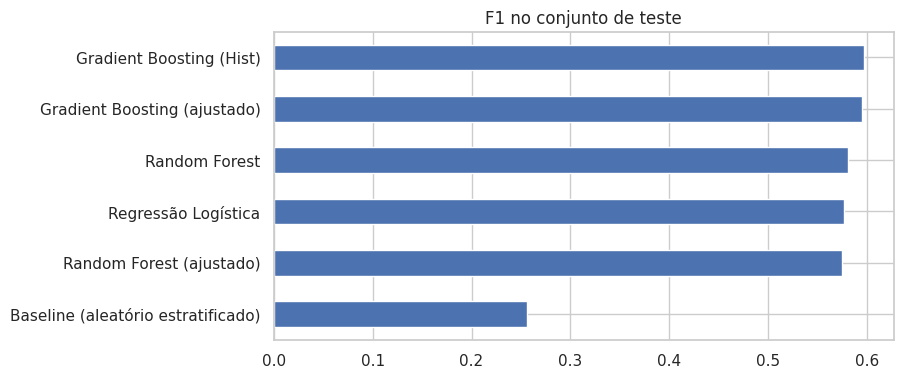

              precision    recall  f1-score   support

 Não-sucesso       0.90      0.73      0.81      2460
     Sucesso       0.49      0.76      0.60       830

    accuracy                           0.74      3290
   macro avg       0.70      0.75      0.70      3290
weighted avg       0.80      0.74      0.76      3290



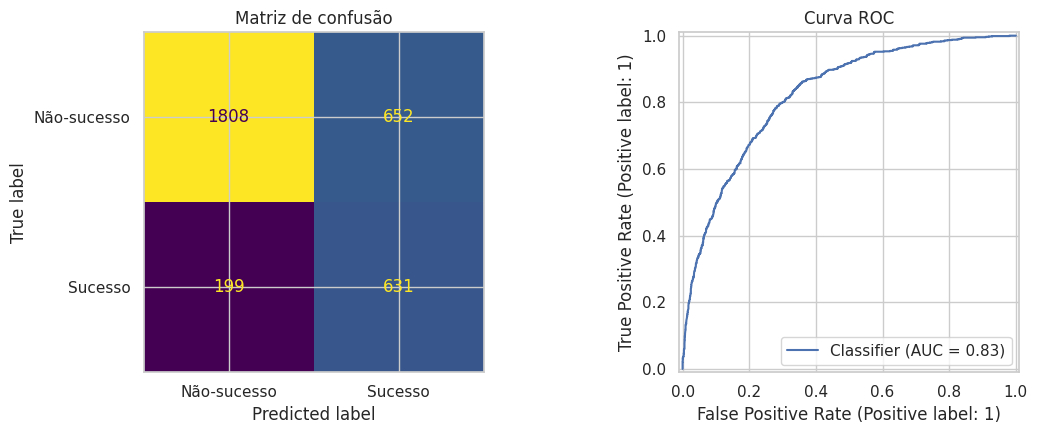

In [21]:
melhor_nome = resultados["F1"].idxmax()
melhor = finais[melhor_nome]
print("Melhor modelo (F1 no teste):", melhor_nome)

resultados["F1"].sort_values().plot(kind="barh", figsize=(8, 4), title="F1 no conjunto de teste")
plt.show()

pred = melhor.predict(X_test)
proba = melhor.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["Não-sucesso", "Sucesso"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Não-sucesso", "Sucesso"], ax=ax[0], colorbar=False)
ax[0].set_title("Matriz de confusão")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].set_title("Curva ROC")
plt.tight_layout(); plt.show()

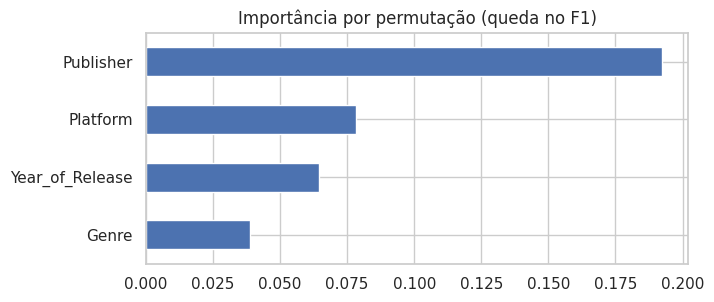

In [22]:
pi = permutation_importance(melhor, X_test, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 3), title="Importância por permutação (queda no F1)")
plt.show()

## 7. Análise de erros

In [23]:
analise = df.loc[idx_test, [COL_NAME, "Platform", "Genre", "Publisher", "Year_of_Release", COL_TARGET]].copy() \
    if COL_NAME in df.columns else df.loc[idx_test, ["Platform", "Genre", "Publisher", "Year_of_Release", COL_TARGET]].copy()
analise["real"] = y_test.values
analise["previsto"] = pred
analise["prob_sucesso"] = proba
analise["erro"] = (analise["real"] != analise["previsto"]).astype(int)

print(f"Taxa de erro geral: {analise['erro'].mean():.1%}")
for col in ["Genre", "Platform"]:
    t = analise.groupby(col)["erro"].agg(["mean", "count"])
    t = t[t["count"] >= 20].sort_values("mean", ascending=False).head(8)
    print(f"\nMaiores taxas de erro por {col} (≥20 jogos no teste):")
    print(t.round(3))

print("\nSucessos que o modelo NÃO identificou (falsos negativos) — maiores vendas:")
display(analise[(analise.real == 1) & (analise.previsto == 0)].sort_values(COL_TARGET, ascending=False).head(10))

print("Jogos previstos como sucesso que não foram (falsos positivos) — maior confiança:")
display(analise[(analise.real == 0) & (analise.previsto == 1)].sort_values("prob_sucesso", ascending=False).head(10))

Taxa de erro geral: 25.9%

Maiores taxas de erro por Genre (≥20 jogos no teste):
             mean  count
Genre                   
Shooter     0.356    250
Racing      0.315    241
Action      0.305    643
Sports      0.295    458
Simulation  0.274    168
Misc        0.258    357
Platform    0.253    170
Fighting    0.247    170

Maiores taxas de erro por Platform (≥20 jogos no teste):
           mean  count
Platform              
2600      0.565     23
PS        0.444    239
WiiU      0.405     37
PS2       0.349    453
X360      0.348    233
N64       0.339     62
PS3       0.296    277
Wii       0.281    263

Sucessos que o modelo NÃO identificou (falsos negativos) — maiores vendas:


,Name,Platform,Genre,Publisher,Year_of_Release,Global_Sales,real,previsto,prob_sucesso,erro
119,Zumba Fitness,Wii,Sports,505 Games,2010.0,6.71,1,0,0.270188,1
205,Warzone 2100,PS,Strategy,Eidos Interactive,1999.0,5.01,1,0,0.416398,1
217,StarCraft II: Wings of Liberty,PC,Strategy,Activision,2010.0,4.84,1,0,0.405477,1
260,Minecraft,PS4,Misc,Sony Computer Entertainment Europe,2014.0,4.32,1,0,0.390045,1
359,Cooking Mama 2: Dinner With Friends,DS,Simulation,505 Games,2007.0,3.58,1,0,0.368843,1
388,Metal Gear Solid V: The Phantom Pain,PS4,Action,Konami Digital Entertainment,2015.0,3.41,1,0,0.448863,1
400,Rugrats: Search For Reptar,PS,Adventure,THQ,1998.0,3.34,1,0,0.434702,1
440,Sonic Rush,DS,Platform,Sega,2005.0,3.12,1,0,0.475668,1
496,Hot Shots Golf 3,PS2,Sports,Sony Computer Entertainment,2001.0,2.89,1,0,0.483782,1
504,The Elder Scrolls III: Morrowind,XB,Role-Playing,Ubisoft,2002.0,2.86,1,0,0.392907,1


Jogos previstos como sucesso que não foram (falsos positivos) — maior confiança:


,Name,Platform,Genre,Publisher,Year_of_Release,Global_Sales,real,previsto,prob_sucesso,erro
6044,Mega Man: Dr. Wily's Revenge,GB,Platform,Nintendo,1991.0,0.28,0,1,0.940854,1
6147,Donkey Kong GB: Dinky Kong & Dixie Kong,GB,Platform,Nintendo,2000.0,0.28,0,1,0.921429,1
7924,Syndicate,X360,Shooter,Electronic Arts,2012.0,0.18,0,1,0.916380,1
4749,The Gunstringer,X360,Shooter,Microsoft Game Studios,2011.0,0.40,0,1,0.913359,1
4373,Wario World,GC,Platform,Nintendo,2003.0,0.44,0,1,0.910594,1
6146,Army of Two: The Devil's Cartel,PS3,Shooter,Electronic Arts,2013.0,0.28,0,1,0.910299,1
9842,Fuse (Insomniac),PS3,Shooter,Electronic Arts,2013.0,0.11,0,1,0.910299,1
5389,Fracture,X360,Shooter,LucasArts,2008.0,0.33,0,1,0.909757,1
5390,Ninja Blade,X360,Action,Microsoft Game Studios,2009.0,0.33,0,1,0.896833,1
13287,Forza Motorsport 3: Ultimate Edition,X360,Racing,Microsoft Game Studios,2010.0,0.04,0,1,0.895602,1


## 8. Comparação: regressão do valor de vendas

Escala log(1+vendas):
  Baseline (média)  MAE=0.269  RMSE=0.407
  Gradient Boosting MAE=0.209  RMSE=0.339  R²=0.305
Erro médio em milhões de unidades: 0.457


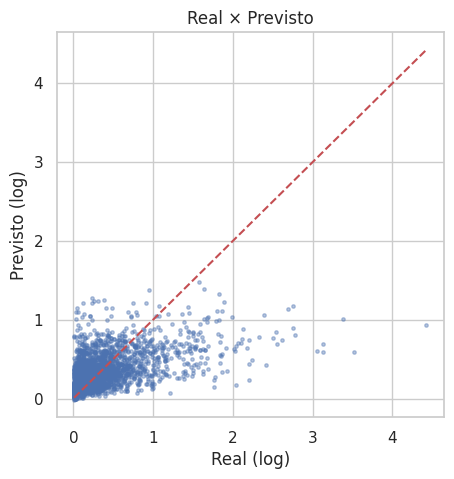

In [24]:
yr = np.log1p(df[COL_TARGET])
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, yr, test_size=0.2, random_state=RANDOM_STATE)

reg = Pipeline([("prep", make_preprocessor()),
                ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]).fit(Xr_train, yr_train)
pr = reg.predict(Xr_test)

base_pred = np.full_like(yr_test, yr_train.mean(), dtype=float)
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
print("Escala log(1+vendas):")
print(f"  Baseline (média)  MAE={mean_absolute_error(yr_test, base_pred):.3f}  RMSE={rmse(yr_test, base_pred):.3f}")
print(f"  Gradient Boosting MAE={mean_absolute_error(yr_test, pr):.3f}  RMSE={rmse(yr_test, pr):.3f}  R²={r2_score(yr_test, pr):.3f}")
print(f"Erro médio em milhões de unidades: {mean_absolute_error(np.expm1(yr_test), np.expm1(pr)):.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(yr_test, pr, s=6, alpha=.4)
lim = [yr_test.min(), yr_test.max()]; plt.plot(lim, lim, "r--")
plt.xlabel("Real (log)"); plt.ylabel("Previsto (log)"); plt.title("Real × Previsto"); plt.show()

## 9. Demonstração de uso

In [25]:
modelo_final = clone(melhor)  
modelo_final.fit(X, y)
joblib.dump(modelo_final, "modelo_vendas.joblib")
print("Modelo salvo: modelo_vendas.joblib")

def prever(plataforma, genero, publisher, ano):
    """Recebe os dados de um jogo e devolve a probabilidade de ele ser um sucesso de vendas."""
    entrada = pd.DataFrame([{"Platform": plataforma, "Genre": genero, "Publisher": publisher, "Year_of_Release": ano}])
    p = modelo_final.predict_proba(entrada)[0, 1]
    veredito = "ALTO potencial de sucesso" if p >= 0.5 else "BAIXO potencial de sucesso"
    print(f"{genero} | {plataforma} | {publisher} | {ano} -> {p:.0%} de chance de sucesso ({veredito})")
    return p

print(f"(sucesso = mais de {limiar:.2f} milhões de unidades vendidas)\n")
exemplos = df[["Platform", "Genre", "Publisher", "Year_of_Release"]].sample(3, random_state=1).values.tolist()
for plat, gen, pub, ano in exemplos:
    prever(plat, gen, pub, int(ano))

Modelo salvo: modelo_vendas.joblib
(sucesso = mais de 0.47 milhões de unidades vendidas)

Action | GBA | Flashpoint Games | 2005 -> 18% de chance de sucesso (BAIXO potencial de sucesso)
Shooter | PS4 | Xseed Games | 2015 -> 33% de chance de sucesso (BAIXO potencial de sucesso)
Action | PS3 | Ubisoft | 2013 -> 79% de chance de sucesso (ALTO potencial de sucesso)


In [26]:
#Plataformas(Consoles) existentes:
print("Plataformas:", sorted(df["Platform"].unique()))

Plataformas: ['2600', '3DO', '3DS', 'DC', 'DS', 'GB', 'GBA', 'GC', 'GEN', 'GG', 'N64', 'NES', 'NG', 'PC', 'PCFX', 'PS', 'PS2', 'PS3', 'PS4', 'PSP', 'PSV', 'SAT', 'SCD', 'SNES', 'TG16', 'WS', 'Wii', 'WiiU', 'X360', 'XB', 'XOne']


In [27]:
#Generos existentes:
print("\nGêneros:", sorted(df["Genre"].unique()))


Gêneros: ['Action', 'Adventure', 'Fighting', 'Misc', 'Platform', 'Puzzle', 'Racing', 'Role-Playing', 'Shooter', 'Simulation', 'Sports', 'Strategy']


In [28]:
#Desenvolvedoras existentes:
print("\nDesenvolvedora:", sorted(df["Publisher"].unique()))


Desenvolvedora: ['10TACLE Studios', '1C Company', '20th Century Fox Video Games', '2D Boy', '3DO', '49Games', '505 Games', '5pb', '7G//AMES', '989 Sports', '989 Studios', 'AQ Interactive', 'ASC Games', 'ASCII Entertainment', 'ASCII Media Works', 'ASK', 'Abylight', 'Acclaim Entertainment', 'Accolade', 'Ackkstudios', 'Acquire', 'Activision', 'Activision Blizzard', 'Activision Value', 'Adeline Software', 'Aerosoft', 'Agatsuma Entertainment', 'Agetec', 'Aksys Games', 'Alawar Entertainment', 'Alchemist', 'Alternative Software', 'Altron', 'Alvion', 'American Softworks', 'Angel Studios', 'Answer Software', 'Aqua Plus', 'Aques', 'Arc System Works', 'Arena Entertainment', 'Aria', 'Arika', 'ArtDink', 'Aruze Corp', 'Ascaron Entertainment', 'Ascaron Entertainment GmbH', 'Asgard', 'Asmik Ace Entertainment', 'Asmik Corp', 'Aspyr', 'Astragon', 'Asylum Entertainment', 'Atari', 'Athena', 'Atlus', 'Avalon Interactive', 'Avanquest', 'Avanquest Software', 'Axela', 'BAM! Entertainment', 'BMG Interactive E

In [29]:
# Teste com uma entrada
prever("PS4", "Action", "Activision", 2015)

Action | PS4 | Activision | 2015 -> 54% de chance de sucesso (ALTO potencial de sucesso)


np.float64(0.5369314663891152)

**Observações da EDA**:
- A distribuição das vendas é muito assimétrica: poucos jogos vendem muito e a maioria vende pouco.
- Há diferenças claras de venda média entre gêneros e plataformas.
- Existem nulos em Year e Publisher.

**Limitações**:
- O modelo usa só plataforma, gênero, publisher e ano. Não conhece franquia, orçamento de marketing, qualidade/nota do jogo, que influenciam muito as vendas.
- Grandes sucessos de franquias conhecidas (outliers) tendem a ser falsos negativos.
- O dataset é histórico e termina em um ano específico; o mercado mudou (vendas digitais não estão incluídas).
- Divisão aleatória treino/teste: jogos do mesmo período aparecem nos dois conjuntos. Uma divisão temporal seria mais realista.

## 10. Conclusões


- **Resultado principal:** o melhor modelo foi o Gradient Boosting, com F1 = 0,60 e ROC AUC = 0,82 no teste. O baseline aleatório ficou em F1 = 0,26. Random Forest (0,59) e Regressão Logística (0,58) chegaram perto. O ajuste de hiperparâmetros não melhorou nenhum dos modelos.
- **O que mais influencia:** o publisher é de longe o fator mais importante (queda de 0,19 no F1 quando é embaralhado). Depois vêm plataforma, ano e gênero.
- **Onde erra:** o modelo encontra 76% dos sucessos, mas só metade dos jogos que ele aponta como sucesso realmente vende bem. Ou seja, ele tende a prever sucesso demais.
- **Limitações e próximos passos:** adicionar franquia/nota da crítica e divisão temporal.